# DeepSubDAS Real Dataset Exploration

## Project: GeoWaveAI

This notebook explores a real Distributed Acoustic Sensing (DAS) dataset from DeepSubDAS.

Previously, we studied geophysical signals and signal preprocessing using synthetic data. In this notebook, we begin examining an actual DAS recording.

### Objectives

1. Load and inspect the real HDF5 dataset.
2. Understand the structure and dimensions of the recording.
3. Calculate basic numerical statistics.
4. Investigate the annotation masks.
5. Visualize the DAS signal and annotation layers.
6. Document the dataset's properties and limitations.

### Dataset Information

- Dataset: DeepSubDAS
- Source: Zenodo
- DOI: 10.5281/zenodo.16014744
- Data format: HDF5
- Recording type: Submarine Distributed Acoustic Sensing (DAS)

**Important:** This notebook performs data exploration only. It does not modify the original recording or train any machine learning model.

## 1. Import Required Libraries

We will use several Python libraries:

- NumPy: Numerical calculations and array operations.
- Pandas: Organizing numerical information into tables.
- Matplotlib: Visualizing signals and annotation masks.
- h5py: Reading the HDF5 dataset.
- pathlib: Working with file and folder paths.
- hashlib: Checking the downloaded file's integrity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import hashlib

from pathlib import Path

print("All required libraries imported successfully.")

All required libraries imported successfully.


## 2. Locate the Project and Dataset

Before loading the recording, we need to locate the project directory and dataset file.

The dataset is stored inside:

data/raw/deepsubdas/

We will automatically identify the project root by searching for the project's pyproject.toml file.

In [2]:
current_path = Path.cwd()

PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "pyproject.toml").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the GeoWaveAI project root."
    )

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "deepsubdas"
    / "20211102T152000_patch1_highnoise_30_100_0_100.h5"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

Project root: e:\GeoWaveAI\geowaveai
Dataset path: e:\GeoWaveAI\geowaveai\data\raw\deepsubdas\20211102T152000_patch1_highnoise_30_100_0_100.h5
Dataset exists: True


## 3. Inspect the HDF5 File Structure

HDF5 is a file format used to store large scientific datasets.

An HDF5 file can contain groups, datasets, and metadata.

We will first inspect the contents of the downloaded file without modifying it.

In [3]:
with h5py.File(DATASET_PATH, "r") as hdf_file:

    print("HDF5 File Structure")
    print("-------------------")

    print("Root keys:", list(hdf_file.keys()))

    print("\nRoot attributes:")

    for key, value in hdf_file.attrs.items():
        print(key, ":", value)

    print("\nDataset Information:")

    for key in hdf_file.keys():

        dataset = hdf_file[key]

        print("\nName:", key)
        print("Type:", type(dataset).__name__)
        print("Shape:", dataset.shape)
        print("Data type:", dataset.dtype)
        print("Attributes:", dict(dataset.attrs))

HDF5 File Structure
-------------------
Root keys: ['mask', 'patch']

Root attributes:

Dataset Information:

Name: mask
Type: Dataset
Shape: (3, 300, 4000)
Data type: float64
Attributes: {}

Name: patch
Type: Dataset
Shape: (300, 4000)
Data type: float32
Attributes: {}


## 4. Load the Recording and Annotation Masks

We identified two datasets inside the HDF5 file:

- patch: The DAS recording data.
- mask: Three annotation layers associated with the recording.

We will load both datasets into NumPy arrays.

The original HDF5 file will remain unchanged.

In [4]:
with h5py.File(DATASET_PATH, "r") as hdf_file:

    patch = hdf_file["patch"][:]
    mask = hdf_file["mask"][:]

print("Data loaded successfully.")

print("\nPatch information:")
print("Shape:", patch.shape)
print("Data type:", patch.dtype)

print("\nMask information:")
print("Shape:", mask.shape)
print("Data type:", mask.dtype)

Data loaded successfully.

Patch information:
Shape: (300, 4000)
Data type: float32

Mask information:
Shape: (3, 300, 4000)
Data type: float64


## 5. Basic Statistical Analysis of the DAS Recording

Now we will investigate the numerical properties of the real recording.

We will calculate:

- Minimum amplitude.
- Maximum amplitude.
- Mean amplitude.
- Standard deviation.
- Number of channels.
- Number of samples per channel.
- Total number of signal values.

These measurements help us understand the recording before applying signal processing.

In [5]:
patch_statistics = {
    "Minimum amplitude": np.min(patch),
    "Maximum amplitude": np.max(patch),
    "Mean amplitude": np.mean(patch),
    "Standard deviation": np.std(patch),
    "Number of channels": patch.shape[0],
    "Samples per channel": patch.shape[1],
    "Total signal values": patch.size,
    "All values finite": np.isfinite(patch).all()
}

patch_stats_df = pd.DataFrame(
    list(patch_statistics.items()),
    columns=["Measurement", "Value"]
)

patch_stats_df

,Measurement,Value
0,Minimum amplitude,-11.866403
1,Maximum amplitude,11.22466
2,Mean amplitude,-0.000765
3,Standard deviation,1.274881
4,Number of channels,300
5,Samples per channel,4000
6,Total signal values,1200000
7,All values finite,True


## 6. Check the Signal for Invalid Values

Real scientific recordings may contain invalid numerical values such as:

- NaN: Not a Number.
- Positive infinity.
- Negative infinity.

These values can cause problems during later signal processing.

We will check whether the recording contains any invalid values.

In [6]:
nan_count = np.isnan(patch).sum()

positive_infinity_count = np.isposinf(patch).sum()

negative_infinity_count = np.isneginf(patch).sum()

finite_count = np.isfinite(patch).sum()

print("Signal Validity Report")
print("----------------------")

print("NaN values:", nan_count)
print("Positive infinity:", positive_infinity_count)
print("Negative infinity:", negative_infinity_count)
print("Finite values:", finite_count)

print(
    "\nAll values are finite:",
    np.isfinite(patch).all()
)

Signal Validity Report
----------------------
NaN values: 0
Positive infinity: 0
Negative infinity: 0
Finite values: 1200000

All values are finite: True


## 7. Analyze the Annotation Masks

The HDF5 file contains an annotation array named mask.

Its shape is:

(3, 300, 4000)

This means that the mask contains three layers, each with the same spatial and sample dimensions as the DAS recording.

We will examine each layer separately.

At this stage, we will call them Layer 0, Layer 1, and Layer 2.

We will not assign definitive meanings to the layers until their annotation mapping has been verified from the dataset documentation or implementation.

In [7]:
mask_statistics = []

for layer_index in range(mask.shape[0]):

    layer = mask[layer_index]

    statistics = {
        "Layer": layer_index,
        "Minimum": np.min(layer),
        "Maximum": np.max(layer),
        "Mean": np.mean(layer),
        "Standard deviation": np.std(layer),
        "Unique values": np.unique(layer).size,
        "All values finite": np.isfinite(layer).all()
    }

    mask_statistics.append(statistics)

mask_stats_df = pd.DataFrame(mask_statistics)

mask_stats_df

,Layer,Minimum,Maximum,Mean,Standard deviation,Unique values,All values finite
0,0,0.000000,0.999994,0.062675,0.197851,273465,True
1,1,0.000000,0.999995,0.062664,0.200945,244930,True
2,2,0.000005,1.000000,0.874661,0.267715,422304,True


## 8. Verify the Relationship Between Mask Layers

We previously observed that the three mask layers appear to form a normalized distribution.

To investigate this, we will calculate the sum of all three layers at every channel and sample position.

If the layers form a normalized distribution, their sum should be approximately equal to 1.

We will check this numerically rather than relying only on visual inspection.

In [8]:
mask_sum = np.sum(mask, axis=0)

print("Mask Sum Analysis")
print("-----------------")

print("Minimum sum:", np.min(mask_sum))
print("Maximum sum:", np.max(mask_sum))
print("Mean sum:", np.mean(mask_sum))
print("Standard deviation:", np.std(mask_sum))

print(
    "Maximum absolute difference from 1:",
    np.max(np.abs(mask_sum - 1.0))
)

within_tolerance = np.mean(
    np.abs(mask_sum - 1.0) < 1e-5
)

print(
    "Positions with sum approximately equal to 1:",
    f"{within_tolerance * 100:.2f}%"
)

Mask Sum Analysis
-----------------
Minimum sum: 0.9999998807907104
Maximum sum: 1.0000001192092896
Mean sum: 0.9999999999606582
Standard deviation: 1.8446711798952535e-08
Maximum absolute difference from 1: 1.1920928955078125e-07
Positions with sum approximately equal to 1: 100.00%


## 9. Dominant Annotation Layer Analysis

At each channel and sample position, we can identify which mask layer has the highest value.

We will use NumPy's argmax function to identify the dominant layer.

This gives us an overview of how the three layers are distributed across the recording.

Important: These counts represent individual channel-sample positions, not independent earthquake events.

In [9]:
dominant_layer = np.argmax(mask, axis=0)

total_positions = dominant_layer.size

dominant_layer_counts = []

for layer_index in range(mask.shape[0]):

    count = np.sum(dominant_layer == layer_index)

    percentage = (count / total_positions) * 100

    dominant_layer_counts.append({
        "Layer": layer_index,
        "Dominant positions": count,
        "Percentage": percentage
    })

dominant_layer_df = pd.DataFrame(
    dominant_layer_counts
)

dominant_layer_df

,Layer,Dominant positions,Percentage
0,0,71131,5.927583
1,1,70653,5.887750
2,2,1058216,88.184667


## 10. Visualize the Real DAS Recording

Now we will visualize the actual DAS recording.

The recording is represented as a two-dimensional array:

- Rows represent recording channels.
- Columns represent sample positions in the stored array.

We will use a seismic color map to visualize variations in the recording.

The axes will initially use channel and sample indices because the sampling rate and physical channel spacing have not yet been verified.

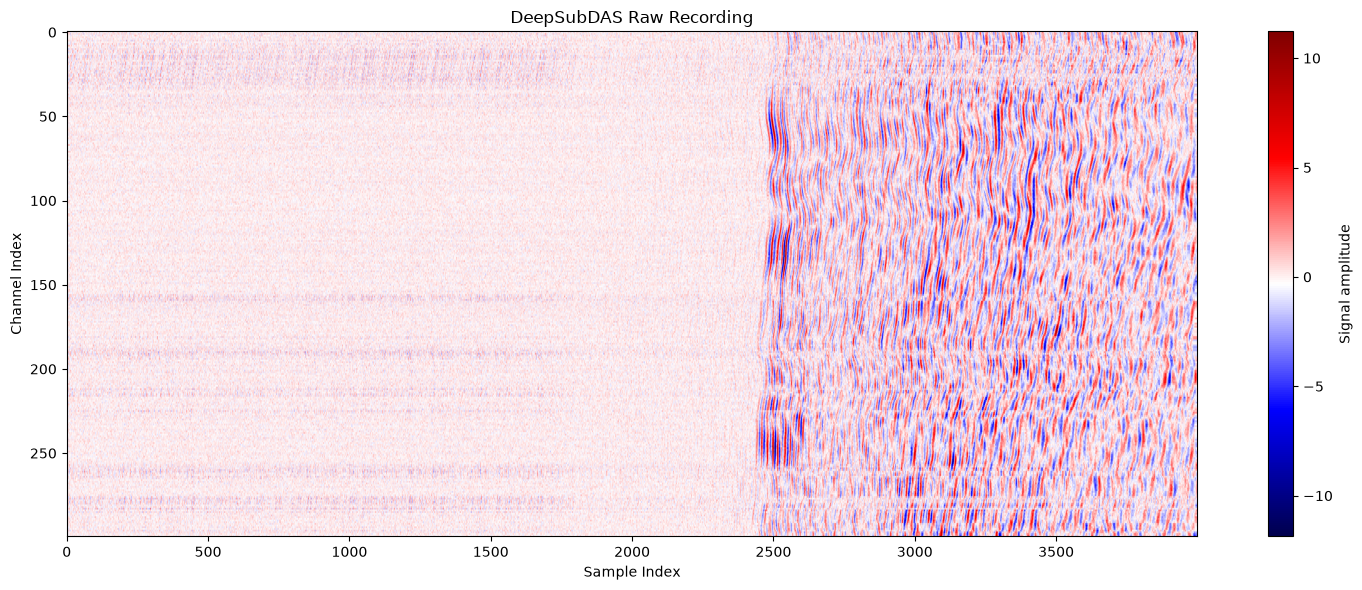

In [10]:
plt.figure(figsize=(15, 6))

plt.imshow(
    patch,
    aspect="auto",
    cmap="seismic",
    origin="upper"
)

plt.colorbar(label="Signal amplitude")

plt.title("DeepSubDAS Raw Recording")

plt.xlabel("Sample Index")
plt.ylabel("Channel Index")

plt.tight_layout()
plt.show()

## 11. Visualize the Three Annotation Layers

We will now visualize the three mask layers independently.

Each layer represents a separate component of the annotation array.

We will use the same color scale for all three plots so their numerical values can be compared.

The layer names remain provisional until their exact mapping is verified.

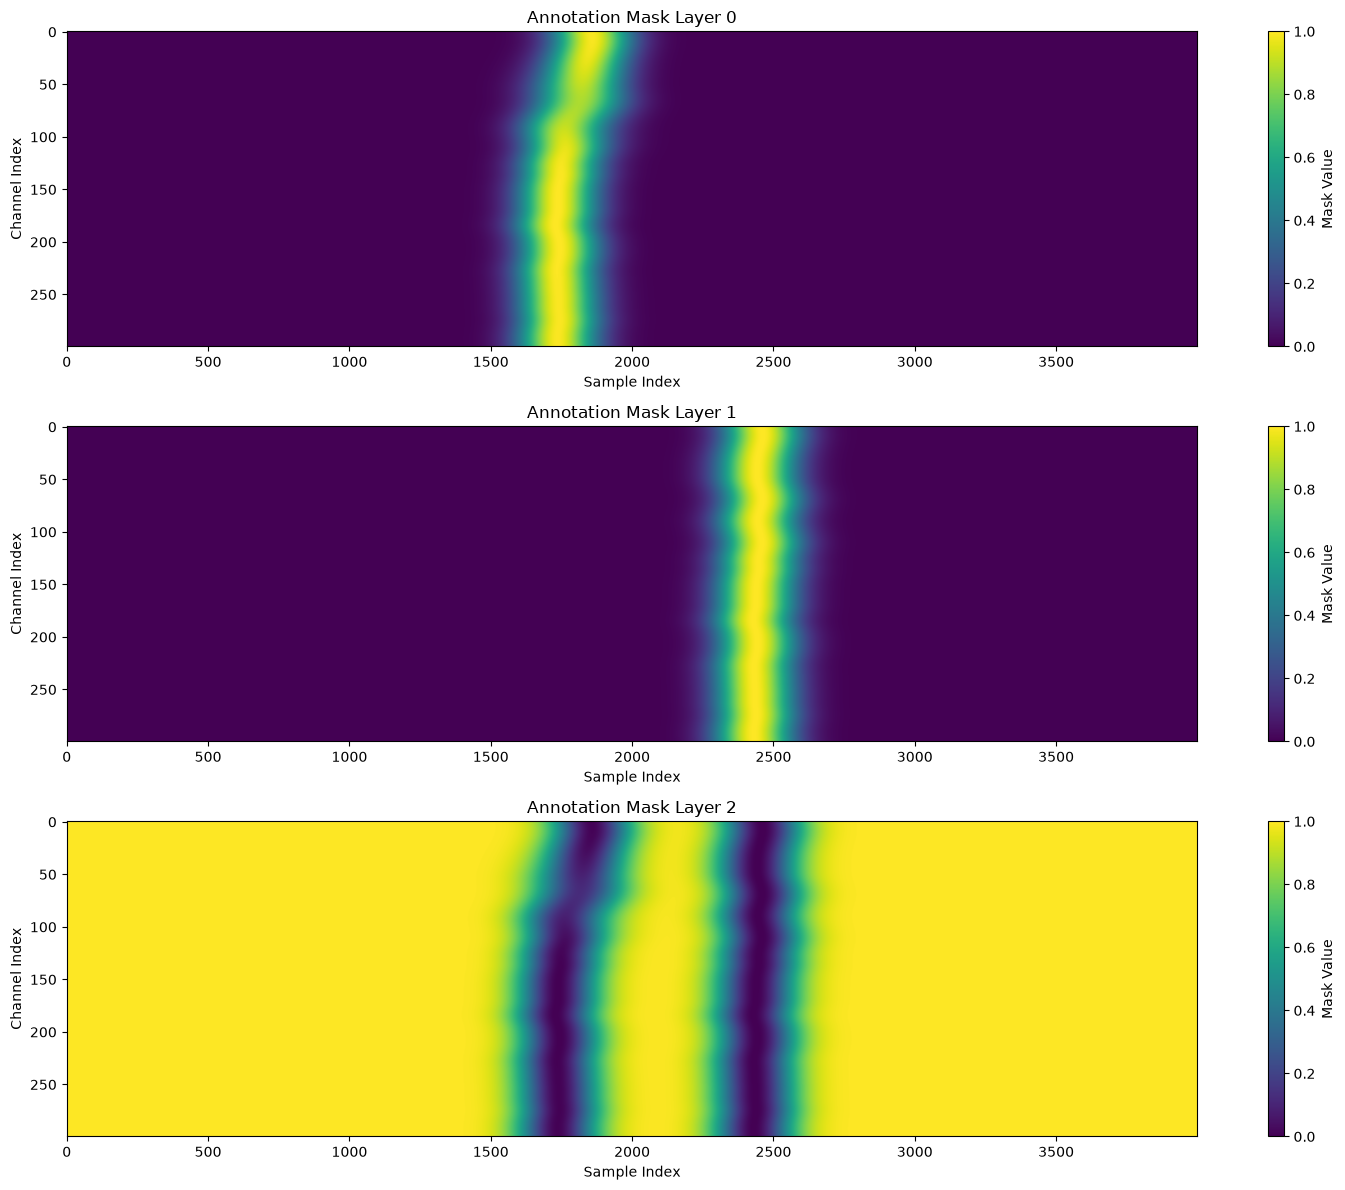

In [11]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 12)
)

for layer_index, ax in enumerate(axes):

    image = ax.imshow(
        mask[layer_index],
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=1,
        origin="upper"
    )

    ax.set_title(f"Annotation Mask Layer {layer_index}")

    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Channel Index")

    fig.colorbar(
        image,
        ax=ax,
        label="Mask Value"
    )

plt.tight_layout()
plt.show()

## 12. Compare the Recording and Annotation Masks

We will display the original DAS recording together with all three annotation layers.

This comparison helps us visually investigate how the annotation patterns relate to the recorded signal.

We will not assume that every visible waveform feature corresponds to a specific annotation class.

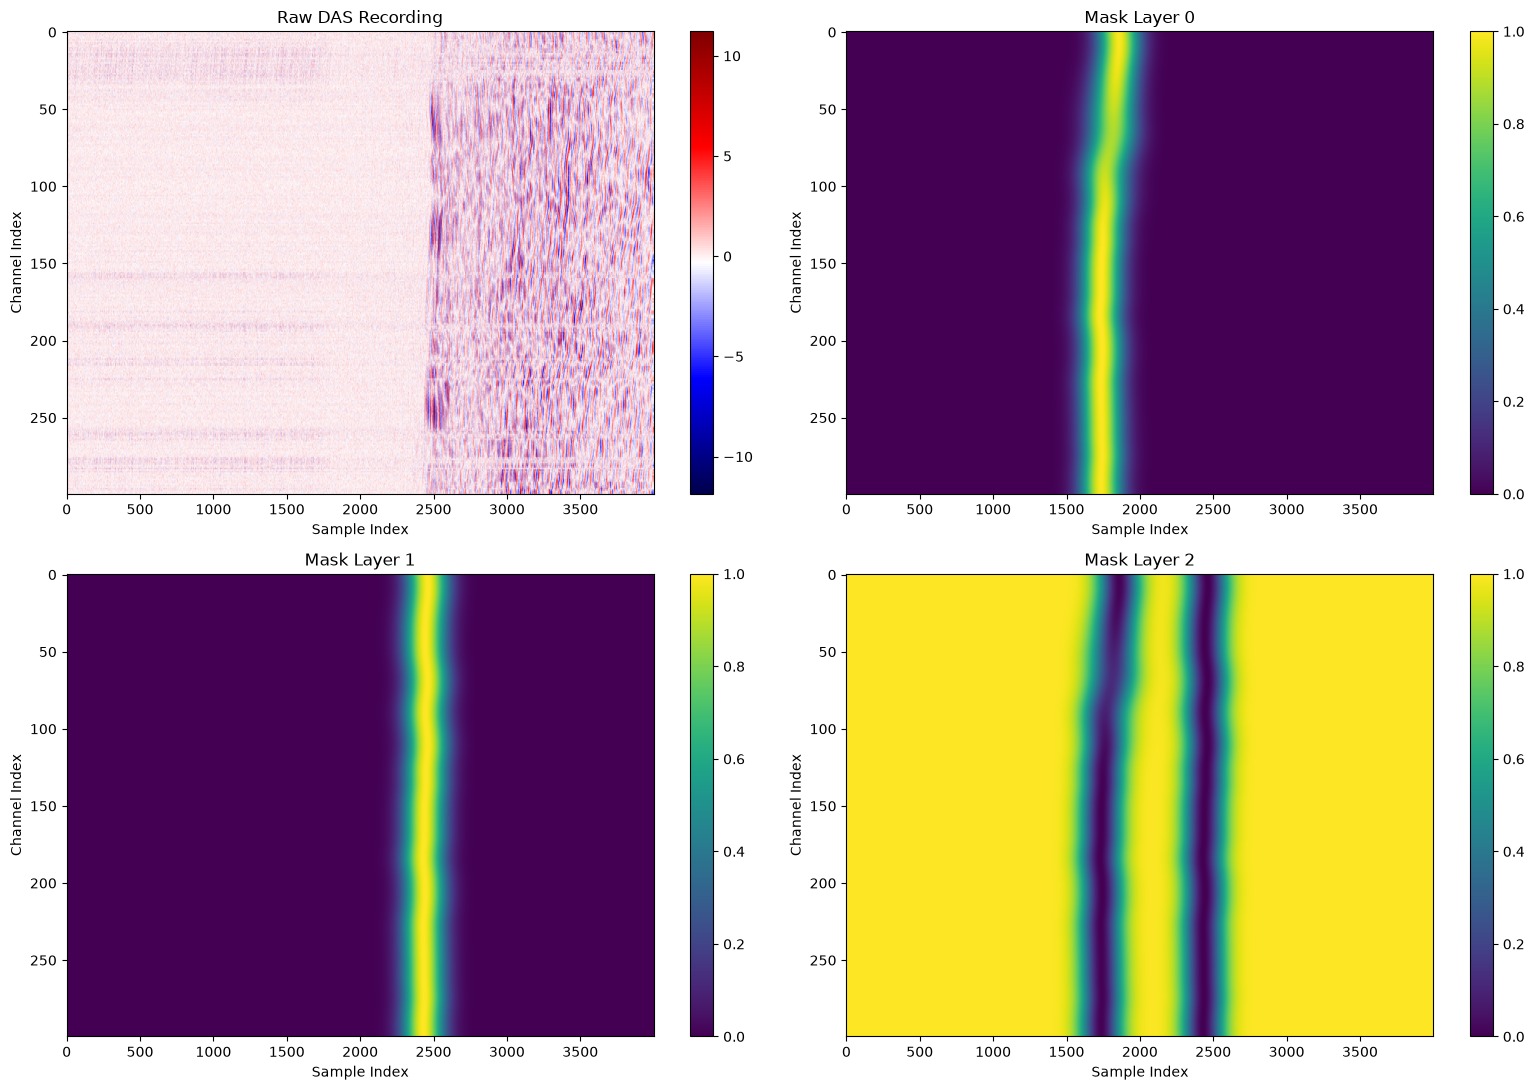

In [12]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

image = axes[0, 0].imshow(
    patch,
    aspect="auto",
    cmap="seismic",
    origin="upper"
)

axes[0, 0].set_title("Raw DAS Recording")
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Channel Index")

fig.colorbar(image, ax=axes[0, 0])


for layer_index in range(3):

    row = (layer_index + 1) // 2
    column = (layer_index + 1) % 2

    image = axes[row, column].imshow(
        mask[layer_index],
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=1,
        origin="upper"
    )

    axes[row, column].set_title(
        f"Mask Layer {layer_index}"
    )

    axes[row, column].set_xlabel("Sample Index")
    axes[row, column].set_ylabel("Channel Index")

    fig.colorbar(
        image,
        ax=axes[row, column]
    )

plt.tight_layout()
plt.show()

## 13. Check the Dataset File Integrity

The original dataset was downloaded from Zenodo.

We previously recorded the official MD5 checksum and verified that the downloaded file matched it.

We will calculate the checksum again to document the file's current integrity.

This operation only reads the file.

In [13]:
md5_hash = hashlib.md5()

with open(DATASET_PATH, "rb") as file:

    for chunk in iter(
        lambda: file.read(1024 * 1024),
        b""
    ):

        md5_hash.update(chunk)

local_md5 = md5_hash.hexdigest()

official_md5 = "3b1bbbeb9358b9e93dbd764d8acb4cc5"

print("Local MD5:", local_md5)
print("Official MD5:", official_md5)

print(
    "Checksum matches:",
    local_md5 == official_md5
)

print(
    "File size (MB):",
    DATASET_PATH.stat().st_size / (1024 ** 2)
)

Local MD5: 3b1bbbeb9358b9e93dbd764d8acb4cc5
Official MD5: 3b1bbbeb9358b9e93dbd764d8acb4cc5
Checksum matches: True
File size (MB): 32.04541015625


## 14. Dataset Exploration Findings

### Confirmed Observations

1. The downloaded dataset is an HDF5 file.
2. The file contains two root datasets: patch and mask.
3. The patch array has dimensions (300, 4000).
4. The mask array has dimensions (3, 300, 4000).
5. The patch data uses float32 values.
6. The mask data uses float64 values.
7. The recording contains finite numerical values.
8. The three mask layers sum to approximately 1 at each position.
9. The original file passes the recorded MD5 checksum verification.

### Important Limitations

1. The sampling rate has not yet been verified.
2. Physical channel spacing has not yet been verified.
3. Physical units of the recording have not yet been verified.
4. The precise meanings and ordering of the three HDF5 mask layers still require verification.
5. The recording is submarine DAS data, so its characteristics should not automatically be assumed to represent land-based DAS recordings.

### Research Importance

This dataset provides a real-world starting point for investigating seismic signal characteristics and annotation behavior.

The next research stages can build on this exploration by studying signal preprocessing, noise characteristics, signal-to-noise ratio, and traditional seismic detection methods.

No machine learning model has been trained in this notebook.

## 15. Conclusion

In this notebook, we successfully explored a real DeepSubDAS recording.

We inspected its HDF5 structure, loaded the signal and annotation arrays, calculated numerical statistics, checked data validity, examined the annotation layers, and visualized the recording.

This completes the initial real-dataset exploration stage of GeoWaveAI.

The original dataset remains unchanged.

Further work will focus on understanding the annotation convention and physical recording metadata before developing signal-processing and detection methods.